# Breast Cancer Diagnosis Prediction Using Machine Learning

**ECH6845 – Chemical Process Data Science**

## 1. Introduction

Breast tumors can be classified as **benign (non-cancerous)** or **malignant (cancerous)**. Accurate classification is important for identifying malignant tumors and supporting timely medical decisions.

Machine learning can identify patterns in diagnostic measurements and predict whether a tumor is benign or malignant. In this project, the **Breast Cancer Wisconsin Diagnostic Dataset** from the UCI Machine Learning Repository is used. It contains **569 samples and 30 numerical features** extracted from digitized images of fine-needle aspirates of breast masses.

Four machine learning algorithms—**Logistic Regression, Random Forest, Gradient Boosting, and XGBoost**—are compared to evaluate their classification performance.

The main objectives of this project are to:

- Explore and preprocess the diagnostic dataset.
- Train and optimize four machine learning models.
- Compare their performance using accuracy, precision, recall, F1-score, and ROC-AUC.
- Identify the most important diagnostic features for classification.

The overall goal is to determine how effectively these machine learning algorithms distinguish between benign and malignant breast tumors.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Define column names
features = [
    "radius", "texture", "perimeter", "area", "smoothness",
    "compactness", "concavity", "concave_points", "symmetry",
    "fractal_dimension"
]

columns = (
    ["ID", "Diagnosis"]
    + [f"{feature}_mean" for feature in features]
    + [f"{feature}_se" for feature in features]
    + [f"{feature}_worst" for feature in features]
)

# Load dataset
df = pd.read_csv(
    "../data/wdbc.data",
    header=None,
    names=columns
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (569, 32)


,ID,Diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


## 2. Dataset Overview and Data Quality

In [3]:
# Dataset information
print("Dataset information:")
df.info()

# Diagnosis categories
print("\nDiagnosis distribution:")
print(df["Diagnosis"].value_counts())

# Missing values
print("\nTotal missing values:")
print(df.isnull().sum().sum())

# Duplicate rows
print("\nDuplicate rows:")
print(df.duplicated().sum())

# Duplicate IDs
print("\nDuplicate IDs:")
print(df["ID"].duplicated().sum())

# Numerical summary
display(df.describe())

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   ID                       569 non-null    int64  
 1   Diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perim

,ID,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


### 2.1 Dataset Quality Assessment

The Breast Cancer Wisconsin Diagnostic Dataset contains 569 samples, including 357 benign tumors (62.74%) and 212 malignant tumors (37.26%).

The dataset contains 30 numerical diagnostic features, one diagnosis column, and one sample identifier.

The data-quality assessment showed:

- No missing values
- No duplicate rows
- No duplicate sample IDs
- All 30 diagnostic features are numerical

Therefore, no missing-value imputation or duplicate removal is required.

The ID column will be excluded from machine learning because it is an identifier rather than a diagnostic feature.

The dataset has a moderate class imbalance, which will be considered during model training and evaluation.

## 3. Exploratory Data Analysis (EDA)

### 3.1 Distribution of Diagnosis Categories

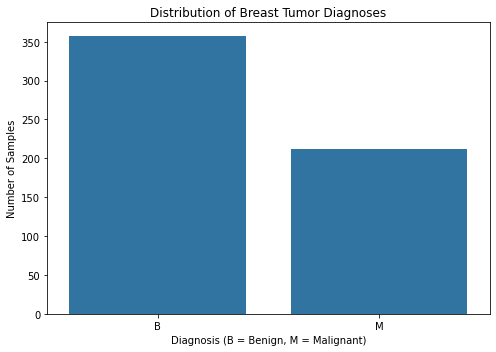

In [4]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="Diagnosis",
    order=["B", "M"]
)

plt.title("Distribution of Breast Tumor Diagnoses")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Number of Samples")

plt.tight_layout()
plt.show()

### 3.2 Tumor Radius by Diagnosis

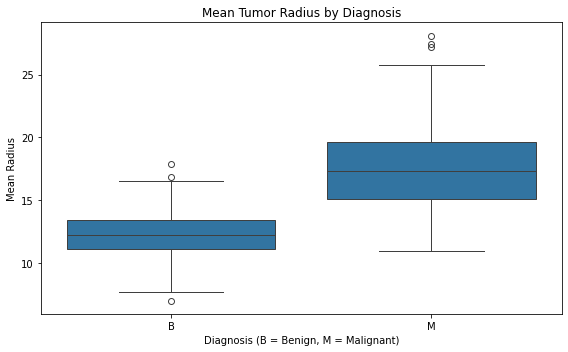

In [5]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Diagnosis",
    y="radius_mean",
    order=["B", "M"]
)

plt.title("Mean Tumor Radius by Diagnosis")
plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
plt.ylabel("Mean Radius")

plt.tight_layout()
plt.show()

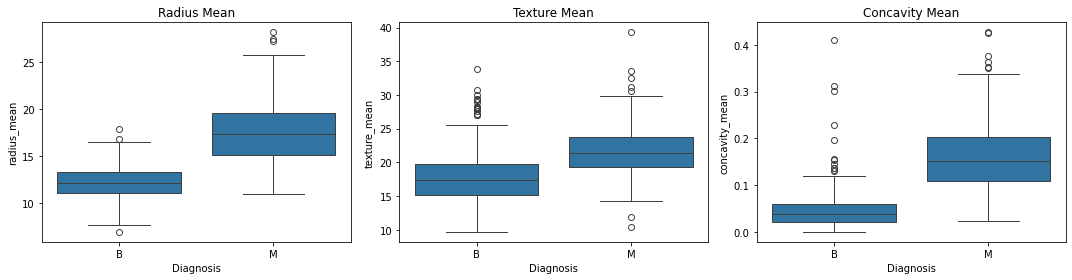

In [6]:
selected_features = [
    "radius_mean",
    "texture_mean",
    "concavity_mean"
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, feature in zip(axes, selected_features):

    sns.boxplot(
        data=df,
        x="Diagnosis",
        y=feature,
        order=["B", "M"],
        ax=ax
    )

    ax.set_title(feature.replace("_", " ").title())
    plt.xlabel("Diagnosis (B = Benign, M = Malignant)")
    ax.set_xlabel("Diagnosis")

plt.tight_layout()
plt.show()

### 3.3.1 Observations from Initial Feature Analysis

The exploratory analysis shows noticeable differences between benign and malignant tumors.

Malignant tumors generally have higher mean radius, texture, and concavity values.

The differences are particularly clear for mean radius and mean concavity, suggesting that these features may be useful for classification.

However, the distributions overlap, indicating that individual features alone may not be sufficient for accurate classification.

Therefore, I will use all 30 diagnostic features when developing the machine learning models.

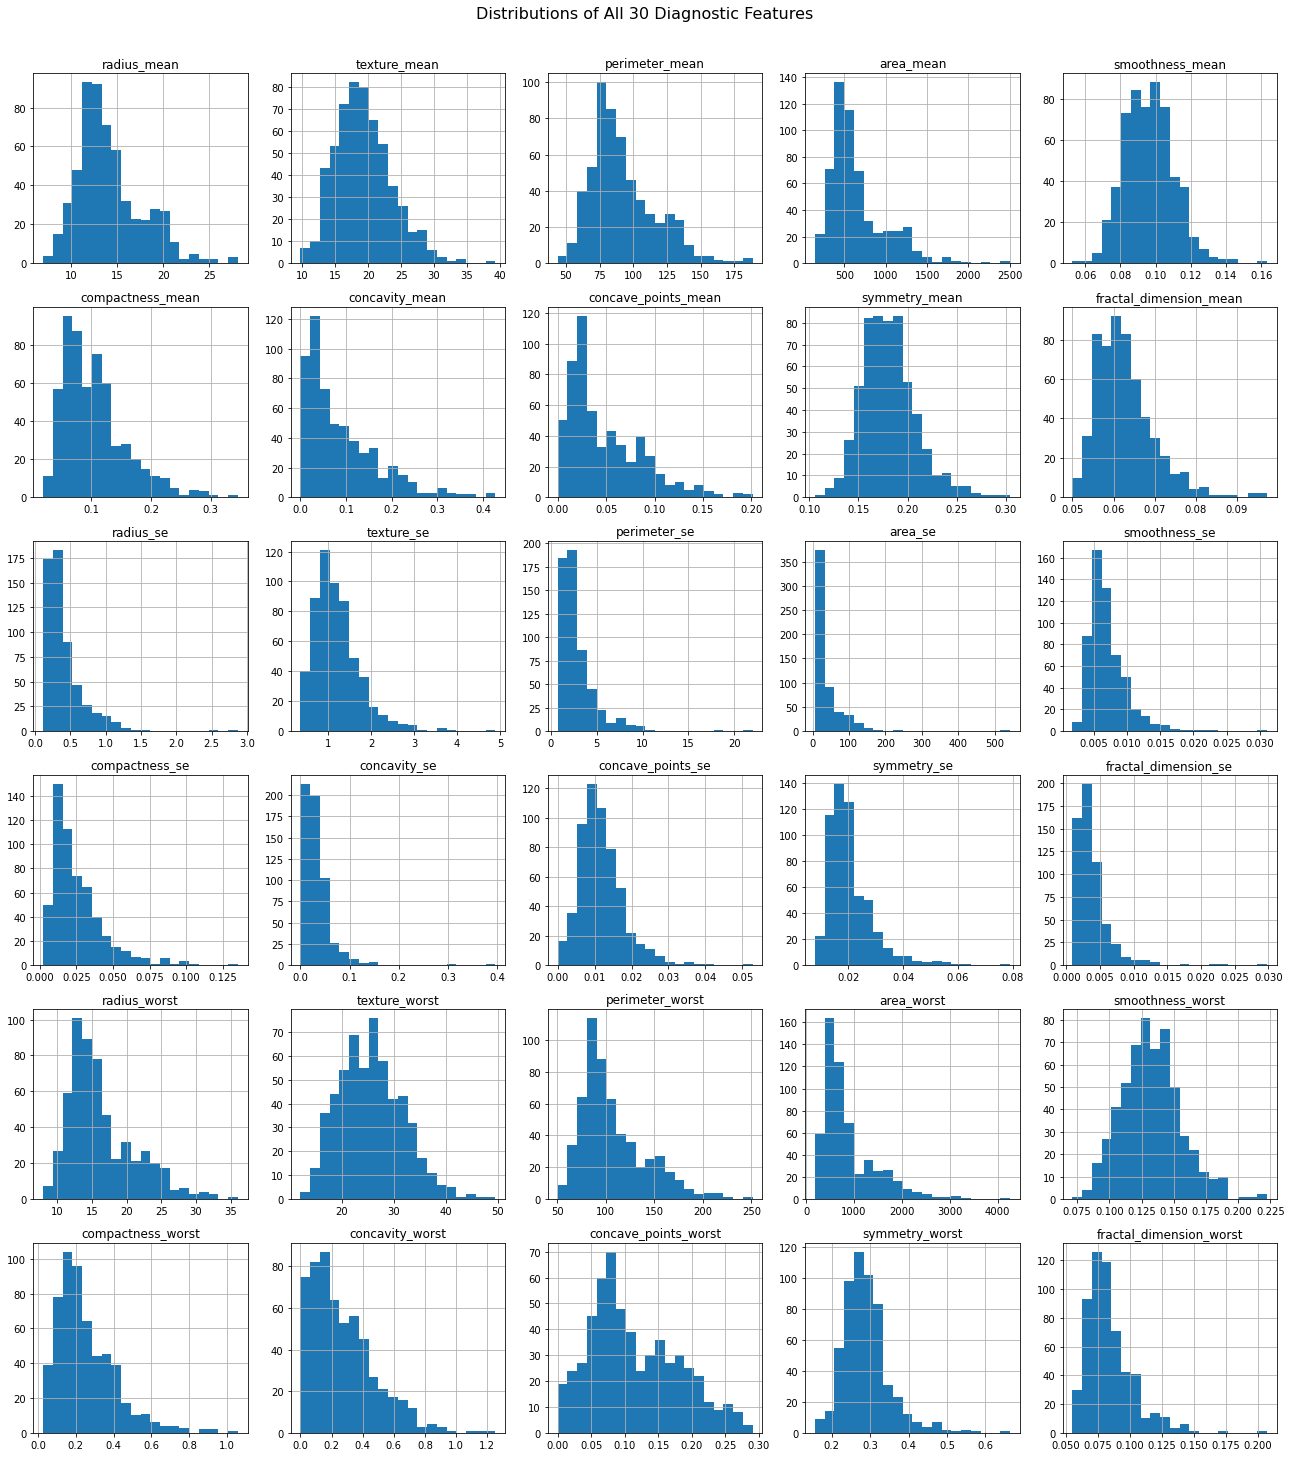

In [7]:
# Select all 30 diagnostic features
feature_columns = df.drop(
    columns=["ID", "Diagnosis"]
).columns

# Create histograms for all features
df[feature_columns].hist(
    figsize=(18, 20),
    bins=20,
    layout=(6, 5)
)

plt.suptitle(
    "Distributions of All 30 Diagnostic Features",
    fontsize=16,
    y=1.01
)

plt.tight_layout()
plt.show()

### 3.4.1 Observations from Feature Distributions

I examined the distributions of all 30 numerical diagnostic features.

The histograms show that the features have different numerical scales. For example, area-related measurements have much larger values than smoothness and concavity measurements.

Several features, including area, concavity, compactness, and some standard-error measurements, show right-skewed distributions. Other features, such as texture and symmetry, show more approximately symmetric distributions.

Some features also contain extreme values that may represent natural variation in tumor characteristics.

These observations suggest that feature scaling will be important for models such as Logistic Regression.

I will initially retain all 30 features, including the extreme observations, and use appropriate preprocessing during model training.

### 3.5 Correlation Analysis of Diagnostic Features

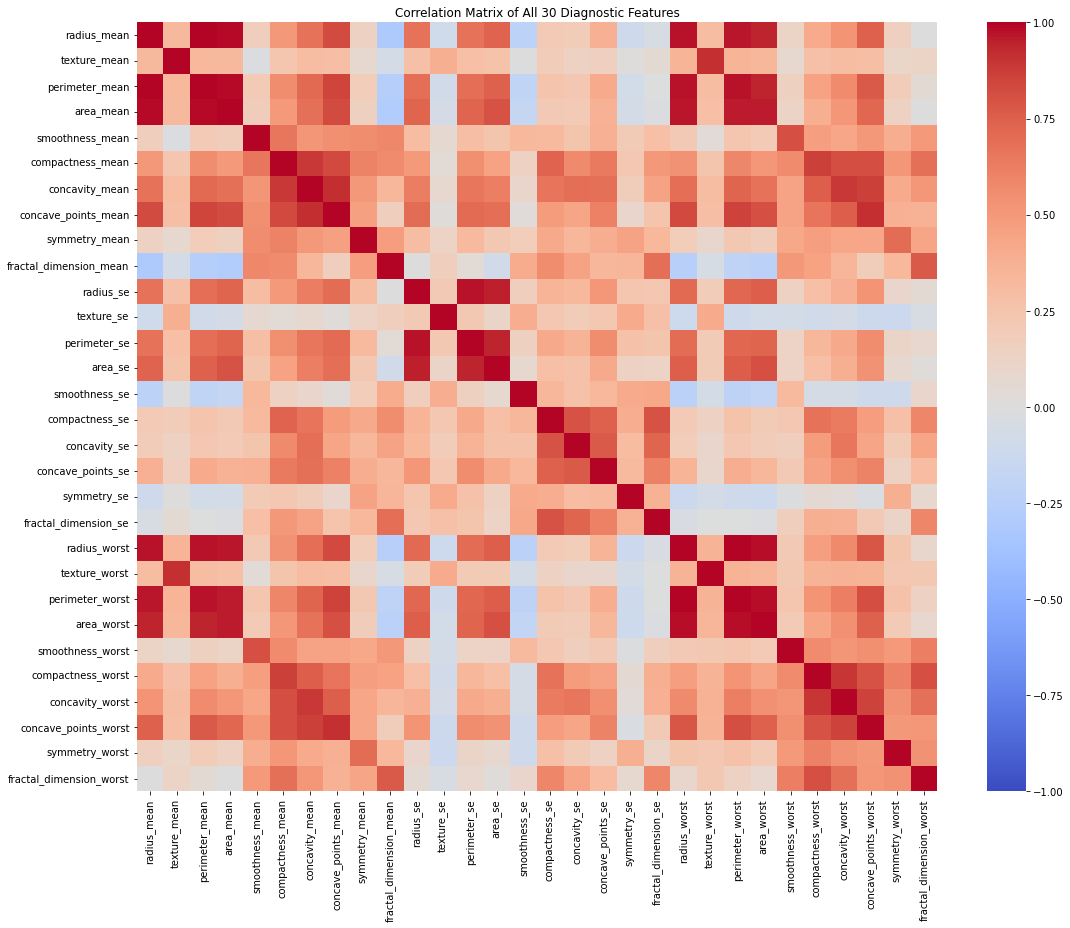

In [8]:
# Select all 30 diagnostic features
feature_columns = df.drop(
    columns=["ID", "Diagnosis"]
).columns

# Calculate correlation matrix
correlation_matrix = df[feature_columns].corr()

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of All 30 Diagnostic Features")

plt.tight_layout()
plt.show()

### 3.5.1 Observations from Correlation Analysis

I calculated the Pearson correlation matrix for all 30 numerical diagnostic features.

The heatmap shows strong positive correlations among several tumor size measurements, particularly radius, perimeter, and area.

Similarly, compactness, concavity, and concave points show positive correlations, indicating relationships among cell nucleus shape characteristics.

Several standard-error features are also strongly correlated.

Some negative correlations are observed between fractal dimension measurements and tumor size-related features.

These findings indicate that some diagnostic features may contain overlapping information.

However, I will retain all 30 features for the initial machine learning models to evaluate their performance using the complete dataset.

Feature correlations may influence model interpretation, particularly for Logistic Regression, and will be considered when discussing the results.

### Additional analysis: Identify highly correlated feature pairs

In [9]:
import numpy as np

# Calculate absolute correlation values
corr_abs = correlation_matrix.abs()

# Keep only the upper triangle
upper_triangle = corr_abs.where(
    np.triu(
        np.ones(corr_abs.shape),
        k=1
    ).astype(bool)
)

# Extract highly correlated pairs
high_corr = (
    upper_triangle.stack()
    .reset_index()
)

high_corr.columns = [
    "Feature 1",
    "Feature 2",
    "Absolute Correlation"
]

# Sort from highest to lowest
high_corr = high_corr.sort_values(
    by="Absolute Correlation",
    ascending=False
)

display(high_corr.head(10))

,Feature 1,Feature 2,Absolute Correlation
1,radius_mean,perimeter_mean,0.997855
391,radius_worst,perimeter_worst,0.993708
2,radius_mean,area_mean,0.987357
57,perimeter_mean,area_mean,0.986507
392,radius_worst,area_worst,0.984015
407,perimeter_worst,area_worst,0.977578
246,radius_se,perimeter_se,0.972794
76,perimeter_mean,perimeter_worst,0.970387
19,radius_mean,radius_worst,0.969539
74,perimeter_mean,radius_worst,0.969476


### 3.5.2 Highly Correlated Diagnostic Features

The correlation analysis identified several strongly correlated feature pairs.

The highest correlation was observed between mean radius and mean perimeter (r = 0.9979), followed by worst radius and worst perimeter (r = 0.9937).

Mean radius and mean area also showed a strong positive correlation (r = 0.9874).

These relationships are expected because radius, perimeter, and area describe related geometric properties of cell nuclei.

The strong correlations suggest that some features contain overlapping information.

This may introduce multicollinearity in Logistic Regression and influence the interpretation of feature importance in tree-based models.

However, all 30 diagnostic features will be retained for the initial machine learning analysis, as the objective is to evaluate the models using the complete feature set.

## 4. Machine Learning Model Development

### 4.1 Defining Input Features and Target Variable

In [10]:
# Use all 30 numerical diagnostic features
X = df.drop(columns=["ID", "Diagnosis"])

# Encode target variable
# Benign = 0, Malignant = 1
y = df["Diagnosis"].map({
    "B": 0,
    "M": 1
})

print("Input feature shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget distribution:")
print(y.value_counts())

Input feature shape: (569, 30)
Target shape: (569,)

Target distribution:
0    357
1    212
Name: Diagnosis, dtype: int64


### Split training and testing data

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", X_train.shape)
print("Testing samples:", X_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())

Training samples: (455, 30)
Testing samples: (114, 30)

Training class distribution:
0    285
1    170
Name: Diagnosis, dtype: int64

Testing class distribution:
0    72
1    42
Name: Diagnosis, dtype: int64




All 30 numerical diagnostic features were selected as input variables, while diagnosis was used as the target variable.

The diagnosis labels were encoded as 0 for benign and 1 for malignant.

The dataset was divided into 80% training data and 20% testing data using stratified sampling.

Stratification maintains approximately the same class proportions in both datasets.

The training data will be used for model development and hyperparameter tuning, while the testing data will be reserved for final model evaluation.

Preprocessing transformations will be fitted using only the training data to prevent data leakage.

### 4.3 Feature Scaling and Model Pipelines

The 30 diagnostic features have different numerical scales. For example, area measurements are much larger than smoothness and concavity measurements.

StandardScaler will be used for Logistic Regression to standardize the features.

Tree-based algorithms, including Random Forest, Gradient Boosting, and XGBoost, do not generally require feature scaling.

Preprocessing will be included within machine learning pipelines to prevent data leakage during cross-validation.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Logistic Regression preprocessing pipeline
lr_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

display(lr_pipeline)

Pipeline(steps=[('scaler', StandardScaler()),
                ('model', LogisticRegression(max_iter=2000, random_state=42))])

### 4.4 Machine Learning Algorithms

I selected four supervised machine learning algorithms to classify breast tumors as benign or malignant using all 30 diagnostic features.

The selected algorithms are:

1. **Logistic Regression:** A linear classification algorithm that estimates the probability of a malignant diagnosis.
2. **Random Forest:** An ensemble learning algorithm that combines multiple decision trees.
3. **Gradient Boosting:** An ensemble algorithm that builds decision trees sequentially to improve predictions.
4. **XGBoost:** An optimized gradient boosting algorithm that uses regularization to improve model generalization.

I will first compare their performance using cross-validation and then tune their hyperparameters.

## 4.5 Initial Model Comparison

In [13]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

models = {
    "Logistic Regression": lr_pipeline,

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ),

    "XGBoost": XGBClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        eval_metric="logloss",
        random_state=42
    )
}

print("Models ready:")
for name in models:
    print(name)

Models ready:
Logistic Regression
Random Forest
Gradient Boosting
XGBoost


### Compare models using 5-fold cross-validation

In [14]:
from sklearn.model_selection import StratifiedKFold, cross_validate
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

results = []

for name, model in models.items():

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring={
            "Accuracy": "accuracy",
            "Precision": "precision",
            "Recall": "recall",
            "F1-score": "f1",
            "ROC-AUC": "roc_auc"
        },
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "Accuracy": scores["test_Accuracy"].mean(),
        "Precision": scores["test_Precision"].mean(),
        "Recall": scores["test_Recall"].mean(),
        "F1-score": scores["test_F1-score"].mean(),
        "ROC-AUC": scores["test_ROC-AUC"].mean()
    })

cv_results = pd.DataFrame(results)

display(cv_results.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.9736,0.9771,0.9529,0.9640,0.9958
1,Random Forest,0.9648,0.9641,0.9412,0.9519,0.9889
2,Gradient Boosting,0.9670,0.9646,0.9471,0.9553,0.9908
3,XGBoost,0.9714,0.9711,0.9529,0.9614,0.9939


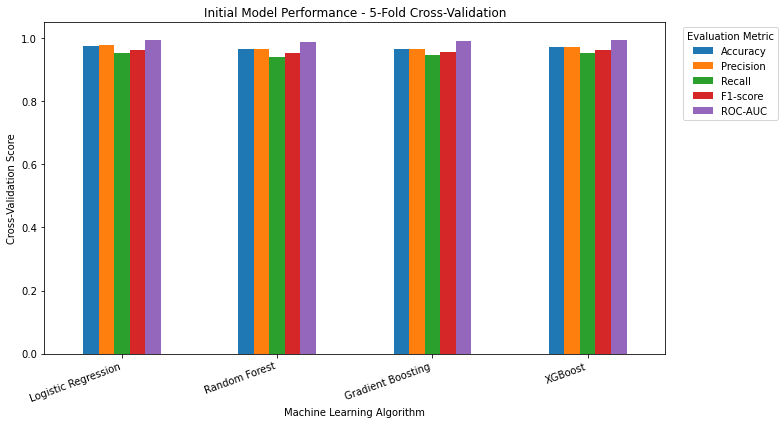

In [15]:
import matplotlib.pyplot as plt

cv_results.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Initial Model Performance - 5-Fold Cross-Validation")
plt.ylabel("Cross-Validation Score")
plt.xlabel("Machine Learning Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(title="Evaluation Metric", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

### 4.5.1 Initial Model Performance

I evaluated four machine learning algorithms using 5-fold stratified cross-validation on the training dataset.

All four algorithms achieved high classification performance, with average accuracy ranging from 96.48% to 97.36%.

Logistic Regression achieved the highest average accuracy (97.36%), F1-score (0.9640), and ROC-AUC (0.9958).

Logistic Regression and XGBoost achieved the highest recall (0.9529), indicating that both models correctly identified a high proportion of malignant tumors during cross-validation.

These results suggest that the diagnostic features contain useful information for distinguishing benign and malignant tumors.

Although Logistic Regression currently performs best, the differences among the algorithms are relatively small.

The next step is to investigate whether hyperparameter tuning can further improve classification performance.

### 4.6 Hyperparameter Tuning

The initial cross-validation results show that all four machine learning models achieve high classification performance. However, the initial models use predefined hyperparameter settings, which may not be optimal for this dataset.

Therefore, hyperparameter tuning is performed using GridSearchCV with 5-fold stratified cross-validation to identify model configurations that may improve predictive performance and generalization.

ROC-AUC is selected as the optimization metric to evaluate the models' ability to distinguish benign and malignant tumors across different classification thresholds.

The tuned models will subsequently be evaluated on the independent test dataset to assess their performance on unseen samples.

The main hyperparameters considered are:

- Logistic Regression: Regularization strength (C) and class weight.
- Random Forest: Number of trees, maximum tree depth, and minimum samples per leaf.
- Gradient Boosting: Number of boosting stages, learning rate, and maximum tree depth.
- XGBoost: Number of trees, learning rate, and maximum tree depth.

The testing dataset will remain untouched during hyperparameter tuning.

In [16]:
param_grids = {
    "Logistic Regression": {
        "model__C": [0.01, 0.1, 1, 10],
        "model__class_weight": [None, "balanced"]
    },

    "Random Forest": {
        "n_estimators": [100, 200],
        "max_depth": [None, 5, 10],
        "min_samples_leaf": [1, 2, 5]
    },

    "Gradient Boosting": {
        "n_estimators": [100, 200],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3]
    },

    "XGBoost": {
        "n_estimators": [100, 200],
        "learning_rate": [0.05, 0.1],
        "max_depth": [2, 3]
    }
}

In [17]:
from sklearn.model_selection import GridSearchCV
import pandas as pd

tuned_models = {}
tuning_results = []

for name, model in models.items():

    print(f"Tuning {name}...")

    grid_search = GridSearchCV(
        estimator=model,
        param_grid=param_grids[name],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True
    )

    grid_search.fit(X_train, y_train)

    tuned_models[name] = grid_search.best_estimator_

    tuning_results.append({
        "Model": name,
        "Best CV ROC-AUC": grid_search.best_score_,
        "Best Parameters": grid_search.best_params_
    })

tuning_df = pd.DataFrame(tuning_results)

display(tuning_df)

Tuning Logistic Regression...
Tuning Random Forest...
Tuning Gradient Boosting...
Tuning XGBoost...


,Model,Best CV ROC-AUC,Best Parameters
0,Logistic Regression,0.995769,"{'model__C': 1, 'model__class_weight': None}"
1,Random Forest,0.988958,"{'max_depth': 10, 'min_samples_leaf': 1, 'n_es..."
2,Gradient Boosting,0.993292,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."
3,XGBoost,0.994427,"{'learning_rate': 0.1, 'max_depth': 2, 'n_esti..."


In [18]:
for name, model in tuned_models.items():
    print(f"\n{name}")
    print("Best parameters:")
    print(
        tuning_df.loc[
            tuning_df["Model"] == name,
            "Best Parameters"
        ].iloc[0]
    )
    


Logistic Regression
Best parameters:
{'model__C': 1, 'model__class_weight': None}

Random Forest
Best parameters:
{'max_depth': 10, 'min_samples_leaf': 1, 'n_estimators': 100}

Gradient Boosting
Best parameters:
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}

XGBoost
Best parameters:
{'learning_rate': 0.1, 'max_depth': 2, 'n_estimators': 200}


### 4.6.1 Hyperparameter Tuning Results

I performed hyperparameter tuning for four machine learning algorithms using GridSearchCV with 5-fold stratified cross-validation.

ROC-AUC was selected as the optimization metric to evaluate the models' ability to distinguish malignant from benign tumors.

Logistic Regression achieved the highest cross-validation ROC-AUC of 0.9958, followed by XGBoost (0.9944), Gradient Boosting (0.9933), and Random Forest (0.9890).

The optimal Logistic Regression configuration used a regularization parameter of C = 1 and no class weighting.

The results indicate that the simpler Logistic Regression model performs competitively with more complex ensemble algorithms.

The tuned models will now be evaluated using the independent testing dataset to assess their generalization performance.

### 4.7 Final Model Evaluation on Testing Data

In [19]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix
)

test_results = []

for name, model in tuned_models.items():

    # Predict class labels
    y_pred = model.predict(X_test)

    # Predict probability of malignant diagnosis
    y_prob = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred),
        "Recall": recall_score(y_test, y_pred),
        "F1-score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    })

test_results_df = pd.DataFrame(test_results)

display(test_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Logistic Regression,0.9649,0.975,0.9286,0.9512,0.9960
1,Random Forest,0.9737,1.000,0.9286,0.9630,0.9929
2,Gradient Boosting,0.9649,1.000,0.9048,0.9500,0.9931
3,XGBoost,0.9649,1.000,0.9048,0.9500,0.9911


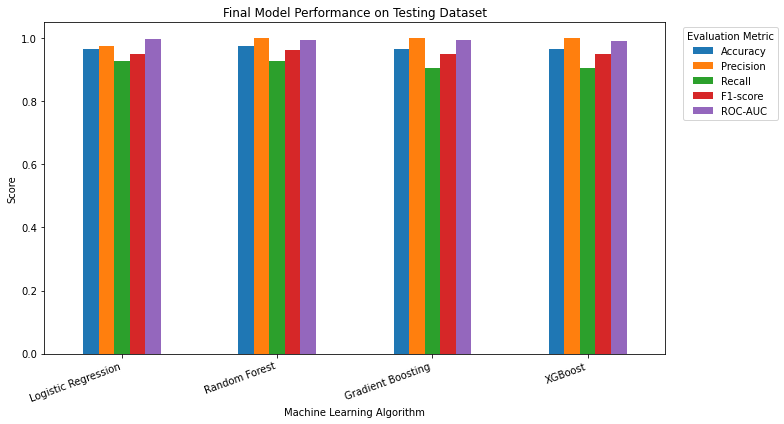

In [21]:
test_results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
].plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Final Model Performance on Testing Dataset")
plt.ylabel("Score")
plt.xlabel("Machine Learning Algorithm")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.legend(
    title="Evaluation Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.tight_layout()
plt.savefig(
    "../figures/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 4.7.1 Final Model Evaluation Results

The four optimized machine learning models were evaluated using the independent testing dataset containing 114 samples.

All models achieved high classification accuracy, ranging from 96.49% to 97.37%.

Random Forest achieved the highest accuracy (97.37%) and F1-score (0.9630), while Logistic Regression achieved the highest ROC-AUC (0.9960).

Logistic Regression and Random Forest achieved the highest malignant recall (92.86%), correctly identifying 39 of the 42 malignant samples.

Gradient Boosting and XGBoost achieved perfect precision but slightly lower recall (90.48%), indicating that they missed more malignant cases.

Overall, Random Forest provided the strongest performance at the default classification threshold, while Logistic Regression demonstrated the strongest discrimination across thresholds.

Although the results are promising, the relatively small testing dataset and lack of external validation limit conclusions about clinical applicability.

### 4.8 Confusion Matrix Analysis

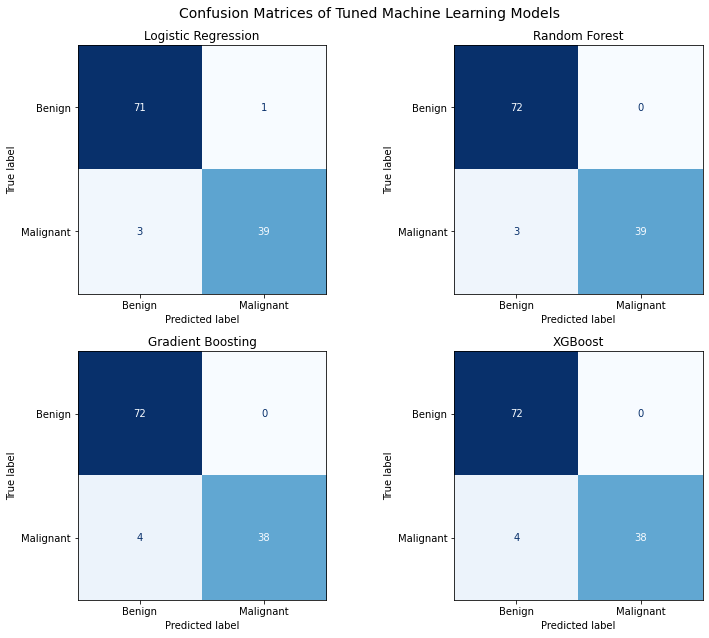

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(2, 2, figsize=(11, 9))

for ax, (name, model) in zip(
    axes.flat, tuned_models.items()
):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["Benign", "Malignant"],
        cmap="Blues",
        colorbar=False,
        ax=ax
    )

    ax.set_title(name)

plt.suptitle(
    "Confusion Matrices of Tuned Machine Learning Models",
    fontsize=14
)

plt.tight_layout()
plt.show()

### 4.8.1 Interpretation of Confusion Matrices

The confusion matrices were used to examine the classification errors of the four optimized machine learning models.

Random Forest achieved the best overall classification performance, correctly identifying all 72 benign tumors and 39 of the 42 malignant tumors.

Logistic Regression correctly identified 71 benign tumors and 39 malignant tumors, with one false positive and three false negatives.

Gradient Boosting and XGBoost correctly classified all 72 benign tumors but incorrectly classified four malignant tumors as benign.

False negatives are particularly important in this classification problem because they represent malignant samples incorrectly predicted as benign.

Although all four models achieved high classification accuracy, none identified every malignant tumor.

These findings highlight the importance of evaluating recall and false-negative rates in addition to overall accuracy.

### 4.9 ROC Curve Comparison

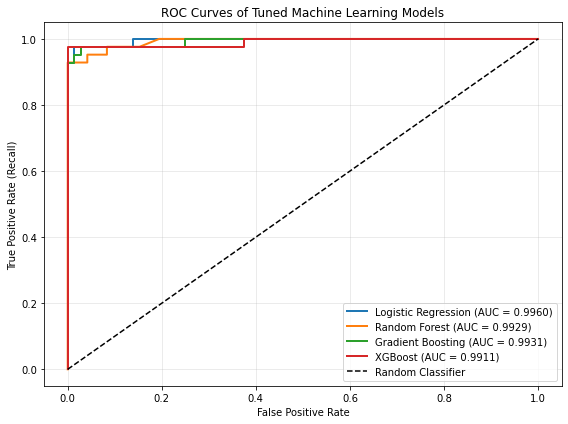

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

for name, model in tuned_models.items():

    # Probability of malignant diagnosis
    y_prob = model.predict_proba(X_test)[:, 1]

    # Calculate ROC curve
    fpr, tpr, thresholds = roc_curve(y_test, y_prob)

    # Calculate ROC-AUC
    auc_score = roc_auc_score(y_test, y_prob)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{name} (AUC = {auc_score:.4f})"
    )

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate (Recall)")
plt.title("ROC Curves of Tuned Machine Learning Models")

plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "../figures/roc_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 4.9.1 Interpretation of ROC Curves

The ROC curves were generated to compare the discrimination performance of the four optimized machine learning models on the independent testing dataset.

All four models achieved ROC-AUC values greater than 0.99, indicating excellent discrimination between benign and malignant tumors.

Logistic Regression achieved the highest ROC-AUC (0.9960), followed by Gradient Boosting (0.9931), Random Forest (0.9929), and XGBoost (0.9911).

Although Random Forest achieved the highest classification accuracy and F1-score, Logistic Regression demonstrated the highest ROC-AUC.

These results indicate that model performance depends on the selected evaluation metric.

The differences among the models were relatively small, and additional validation would be necessary to determine whether the observed differences are statistically meaningful.

### 4.10 Feature Importance Analysis

In [25]:
import pandas as pd
import matplotlib.pyplot as plt

# Retrieve the tuned Random Forest model
rf_model = tuned_models["Random Forest"]

# Calculate feature importance
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": rf_model.feature_importances_
})

# Sort features by importance
feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

# Display all 30 features
display(feature_importance)

,Feature,Importance
23,area_worst,0.151412
27,concave_points_worst,0.126497
20,radius_worst,0.093475
22,perimeter_worst,0.083642
7,concave_points_mean,0.081082
2,perimeter_mean,0.077126
0,radius_mean,0.061990
6,concavity_mean,0.050818
3,area_mean,0.045916
26,concavity_worst,0.030022


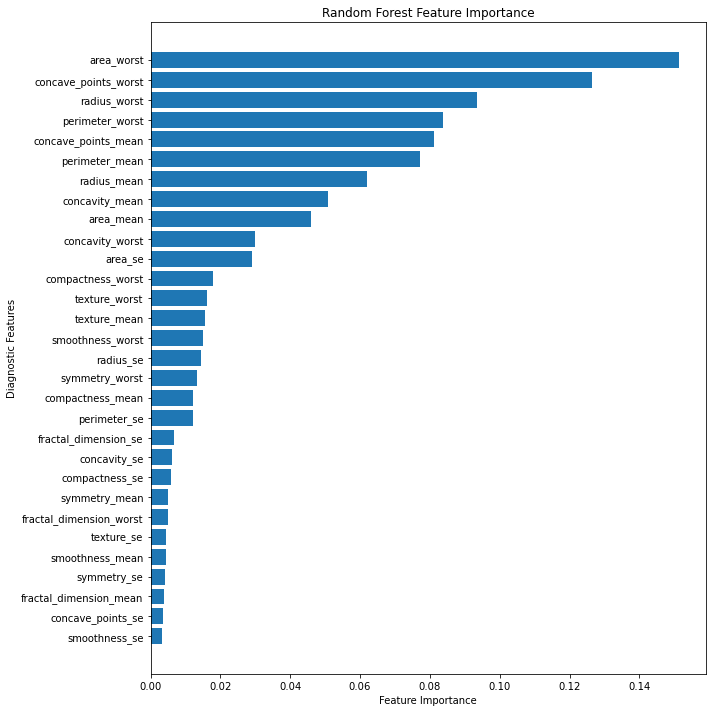

In [27]:
plt.figure(figsize=(10, 10))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.title("Random Forest Feature Importance")
plt.xlabel("Feature Importance")
plt.ylabel("Diagnostic Features")

plt.tight_layout()
plt.savefig(
    "../figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### 4.10.1 Interpretation of Feature Importance

Random Forest feature importance was calculated to investigate the relative contributions of all 30 diagnostic features to tumor classification.

The most important feature was `area_worst` (0.1514), followed by `concave_points_worst` (0.1265), `radius_worst` (0.0935), and `perimeter_worst` (0.0836).

These results indicate that measurements related to cell nucleus size and shape irregularity are particularly useful for distinguishing benign and malignant samples.

Several standard-error and fractal-dimension features showed relatively low importance.

However, the correlation analysis revealed strong relationships among several diagnostic measurements. Therefore, correlated features may share predictive information, which can influence their individual importance scores.

All 30 features were retained during model training, as required for the project.

The importance values represent relative contributions within the Random Forest model and should not be interpreted as causal effects or direct measures of clinical significance.

## 5. Conclusion

The objective of this project was to develop and compare machine learning models for classifying breast tumors as benign or malignant using the Breast Cancer Wisconsin Diagnostic Dataset.

All 30 diagnostic features were included in the model development process.

Four machine learning algorithms were evaluated using stratified cross-validation, hyperparameter tuning, and independent test-set evaluation.

The main findings were:

- Random Forest achieved the highest test accuracy of 97.37% and F1-score of 0.9630.
- Logistic Regression achieved the highest ROC-AUC of 0.9960.
- Logistic Regression and Random Forest achieved the highest malignant recall of 92.86%.
- Tumor size and nuclear shape measurements were among the most important features for classification.

Overall, the results demonstrate that machine learning algorithms can effectively distinguish benign and malignant samples within this dataset.

However, the presence of false-negative predictions and the limited dataset size indicate that further validation is necessary before considering practical clinical applications.

